# Connectome Surrogates vs. Connectivity-Informed Source Reconstruction

Tests how wCSET/CSET (source reconstruction methods that use a connectome's
graph-Laplacian eigenspectrum as a spatial prior) perform when given different
connectome *construction methods* instead of the true/empirical connectome, evaluated
against sLORETA as a non-connectivity-informed reference. See
`connectome_surrogates_plan.md` (next to this notebook) for the full plan and the
empirical verification behind each design choice.

Companion to `tutorials/analysis/connectomic/sabotage_connectome.ipynb` (same harness
shape -- wCSET/CSET at hrp/pp, `MetricSuite`-based -- but that study varies *corruption
severity* of the empirical connectome; this one varies *construction method* instead).

Scale: N=15 regions (scaled up from the N=5 pilot pass once the pipeline was validated).

## 🧪 - Experiment setup
- `fwd_sim`/`fwd_inv`: simulation-time and inversion-time forward solutions for
  `sub="simf10"` (deliberately different, inverse-crime avoidance) -- surrogates are
  built at `fwd_sim`'s resolution (matches `con`'s 7465 dipoles), solving uses `fwd_inv`
- `con`/`eig`: the true connectome and its already-computed eigenspectrum
- `parc`/`ras2tkras`/`probcon`: needed to rebuild the `connectome-atlas.ipynb` fused
  surrogate exactly
- `region_subset`: 5 regions picked via the same FPS approach as `simulation_spike.ipynb`
- `tasks`: reuses `sub-simf10`'s already-generated 473-region dataset (fixed
  `snr_target=10`) -- filtered down to the 5 selected regions, no new simulation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import load_npz

import mindmap as mm
import mne

from mindmap.analysis.functional.common.metric import find_peak_localization_error
from mindmap.analysis.functional.inverse import InverseTask, run_parallel_pipeline

dm = mm.io.TutoManager("../../config.yml")
sub = "simf10"

# subject-level data
fwd_sim = dm.load(sub, "fwd", desc="sim")
fwd_inv = dm.load(sub, "fwd", desc="inv")
con = dm.load(sub, "con")
eig_true = dm.load(sub, "eig")
parc = dm.load(sub, "dseg", space="fs", segmentation="multiconn2022", scale="4")
ras2tkras = dm.load(sub, "ras2tkras")
probcon = dm.load_ref("REF_CON")

dipole_positions = mm.anatomy.source_space.get_dipole_positions(fwd_inv["src"]) * 1000
simulator_dir = dm.roots["sim"]/f"sub-{sub}"/"simulator"

print(f"con shape: {con.shape}, eig vec shape: {eig_true['vec'].shape}")

con shape: (7465, 7465), eig vec shape: (7465, 7465)


## 🔒 - Step 0: verify data integrity

Known trap (see memory `stale-connectome-bug`): `con`/`eig` and the `Simulator`'s own
saved head-model state can silently diverge (different regeneration schedules), which
once made a corrupted connectome spuriously outperform the "clean" one. Re-check before
trusting anything below.

In [2]:
conn_lengths = load_npz(simulator_dir/"conn_lengths.npz").toarray()
assert np.allclose(conn_lengths, con), "con does not match the Simulator's own saved connectome!"

strength_true = np.divide(1, con, out=np.zeros_like(con), where=con > 0)
fresh_vec, fresh_val = mm.analysis.connectivity.compute_cst(strength_true)
assert np.allclose(fresh_val, eig_true["val"]), "eig val is not bit-identical to a fresh compute_cst!"
assert np.allclose(np.abs(fresh_vec), np.abs(eig_true["vec"])), "eig vec is not bit-identical to a fresh compute_cst!"

print("con/eig/Simulator are mutually consistent.")

con/eig/Simulator are mutually consistent.


## 🎯 - Step 1: region subset + existing sub-simf10 runs

`sub-simf10` already has 473 runs (one per parcellation region, fixed `snr_target=10`)
-- no new simulation needed, just select which existing runs to evaluate.

In [3]:
region_subset = mm.anatomy.parcellation.select_uniform_regions(
    fwd_sim["src"], parc, ras2tkras, n_regions=15, cortex_only=True, seed=0,
)
print("Selected regions:", region_subset)

df_index = pd.read_csv(dm.roots["sim"]/f"sub-{sub}"/"simulation_index.tsv", sep="\t")
df_index["region"] = df_index["source_index_list"].str.strip("[]'\"")
df_subset = df_index[df_index["region"].isin(region_subset)].copy()

print(f"{len(df_subset)} of {len(df_index)} runs selected (expected {len(region_subset)}).")

tasks = [
    InverseTask(
        run=int(row["run"]),
        simulator_dir=simulator_dir,
        fave=dm.get_path(sub, "ave", run=int(row["run"])),
        fcov=dm.get_path(sub, "cov", run=int(row["run"])),
        fgold=dm.get_path(sub, "gold", run=int(row["run"])),
        fsource=dm.get_path(sub, "source", run=int(row["run"])),
        target_snr=row["target_snr"],
    )
    for _, row in df_subset.iterrows()
]

Selected regions: ['ctx-rh-rostralanteriorcingulate_1', 'ctx-lh-lateraloccipital_1', 'ctx-lh-middletemporal_3', 'ctx-rh-supramarginal_4', 'ctx-lh-precentral_16', 'ctx-rh-inferiortemporal_2', 'ctx-lh-rostralmiddlefrontal_4', 'ctx-rh-caudalmiddlefrontal_3', 'ctx-lh-temporalpole_1', 'ctx-rh-superiorparietal_8', 'ctx-lh-isthmuscingulate_2', 'ctx-rh-fusiform_1', 'ctx-lh-inferiorparietal_3', 'ctx-lh-precentral_9', 'ctx-lh-superiorfrontal_10']
15 of 473 runs selected (expected 15).


## 🧬 - Step 2: build the 2 surrogate connectomes (+ true)

Both built at `fwd_sim`'s resolution (matches `con`'s 7465 dipoles). See
`connectome_surrogates_plan.md` for why atlas-only and geometric-only/empirical-params
were dropped from the original 4-surrogate plan.

- **Fused**: exact `connectome-atlas.ipynb` recipe (atlas upscaling + geometric gap-fill).
- **Geometric-only, atlas params**: `connectome_from_geometry` alone, with the new
  `inter_hemi_mirror=True` (homotopic mirror-matching instead of the cruder Euclidean
  `inter_hemi_dist` threshold) -- confirmed this reaches a single connected component.

In [4]:
# --- Fused (connectome-atlas.ipynb recipe, verbatim) ---
consistency = np.nan_to_num(probcon["matrices"]["consistency"][:,:])
length      = np.nan_to_num(probcon["matrices"]["length"][:,:])
number      = np.nan_to_num(probcon["matrices"]["numbStlines"][:,:])

atlas_mask = np.bitwise_and(consistency > 65, length > 0)
atlas_mask = np.bitwise_and(atlas_mask, number > 0)
atlas = length * atlas_mask

con_atlas = mm.analysis.connectivity.connectome_from_atlas(
    fwd_sim["src"], parc, atlas, ras2tkras, sparsity=0.14, deterministic=True,
)
con_geom_fill = mm.analysis.connectivity.connectome_from_geometry(
    fwd_sim["src"], maximum_dist=22, maximum_neigh=35, weights=True,
)
con_fused = con_atlas.copy()
fill_idx = np.argwhere((con_geom_fill > 0) & (con_atlas == 0))
con_fused[fill_idx[:,0], fill_idx[:,1]] = con_geom_fill[fill_idx[:,0], fill_idx[:,1]]

# --- Geometric-only, atlas params, with homotopic interhemispheric connections ---
con_geom_atlas = mm.analysis.connectivity.connectome_from_geometry(
    fwd_sim["src"], maximum_dist=22, maximum_neigh=35, weights=True, inter_hemi_mirror=True,
)

# --- Binary versions ---
con_fused_bin = (con_fused > 0).astype(float)
con_geom_atlas_bin = (con_geom_atlas > 0).astype(float)

surrogates = {
    "fused": con_fused,
    "fused_bin": con_fused_bin,
    "geom_atlas": con_geom_atlas,
    "geom_atlas_bin": con_geom_atlas_bin,
}

## 🌀 - Step 3: eigenspectra (once, upfront -- not per reconstruction task)

Length -> strength inversion matches exactly how the shipped `eig` was built (a no-op
for the binary matrices, since 1/1=1); eigendecomposition dominates wall time
(~18s/call on this graph per the sabotage study), so this happens once per surrogate,
shared across every region below.

In [5]:
connectomes = {"true": eig_true}

for label, con_surrogate in surrogates.items():
    strength = np.divide(1, con_surrogate, out=np.zeros_like(con_surrogate), where=con_surrogate > 0)
    eigvec, eigval = mm.analysis.connectivity.compute_cst(strength)
    connectomes[label] = {"vec": eigvec, "val": eigval}

print("Connectomes ready:", list(connectomes.keys()))

Connectomes ready: ['true', 'fused', 'fused_bin', 'geom_atlas', 'geom_atlas_bin']


## 🔧 - Step 4: reconstruction (5x wCSET + 5x CSET + 1x sLORETA, at hrp/pp)

Same `preprocess_hrp_pp` as `inverse-noisesweep.ipynb`, unchanged (gold-projection-based
hrp/pp, immune to noise). `reconstruct_fn` now loops over the 5 precomputed
`(label, eig)` pairs instead of a single connectome, building one `wCSET`/`CSET` per
pair (same lambda2 convention as before: auto-estimated for wCSET/sLORETA, fixed `0.1`
for CSET) plus one `sLORETA` reference -- 11 solutions per run. `postprocess_score`
scores each against that run's `gold` with the same 5 metrics, tagged with `label`
(e.g. `"wcset_fused"`, `"cset_geom_atlas_bin"`, `"sloreta"`) -- the swept axis here is
connectome-construction identity, not noise level.

In [6]:
def preprocess_hrp_pp(ctx):
    ave, gold, simulator = ctx["ave"], ctx["gold"], ctx["simulator"]

    # hrp/pp picked from this run's own noise-free gold, projected to sensor space with
    # the *simulation* forward (simulator.hm.fwd matches gold's source space) -- immune
    # to noise by construction, unlike finding the peak in `ave` directly.
    clean_ave = mne.apply_forward(simulator.hm.fwd, gold, ave.info)
    hrp_idx = mm.analysis.eeg.get_rising_phase(clean_ave, ratio=0.5, as_idx=True)[0]
    pp_idx = mm.analysis.eeg.get_rising_phase(clean_ave, ratio=1, as_idx=True)[0]

    phase_data = mne.EvokedArray(ave.data[:, [hrp_idx, pp_idx]], ave.info, tmin=0, nave=ave.nave, kind=ave.kind)

    return {"phase_data": phase_data, "hrp_idx": hrp_idx, "pp_idx": pp_idx}


def make_reconstruct(fwd, connectomes):
    """connectomes: dict[label -> {"vec":..., "val":...}]. One wCSET + one CSET per
    connectome, plus a single sLORETA reference (not connectivity-informed)."""
    def reconstruct(ctx):
        data, ncov = ctx["phase_data"], ctx["ncov"]

        # SNR estimated from the real, full-time-reference `ave` -- not `phase_data`,
        # whose tmin=0 fake time axis puts the real baseline window (negative time)
        # entirely outside its range. That silently produced an empty baseline slice
        # (NaN mean, "Mean of empty slice" warning), and crucially
        # max(0.01, 1.0/nan**2) evaluates to 0.01 (not NaN) in this argument order --
        # so lambda2_auto was silently pinned to the floor value every time, not
        # visibly broken. `ave` has the correct time reference, so this is fixed.
        snr, _ = mm.analysis.eeg.estimate_evoked_snr(
            evoked=ctx["ave"], baseline=ctx["simulator"].epoch_config.baseline, noise_cov=ncov)
        lambda2_auto = max(0.01, 1.0 / (snr.max() ** 2))

        solutions = {}
        for label, eig in connectomes.items():
            inv_wcset = mm.analysis.inverse.wCSET(
                forward=fwd, noise_cov=ncov, depth=0.5,
                eigenvectors=eig["vec"], eigenvalues=eig["val"],
                harm=5, harmonic_method="lowpass",
            )
            solutions[f"wcset_{label}"] = inv_wcset.solve(data, lambda2_auto)

            inv_cset = mm.analysis.inverse.CSET(forward=fwd, noise_cov=ncov, depth=0.8, eigenvectors=eig["vec"])
            solutions[f"cset_{label}"] = inv_cset.solve(data, lambda2=0.1)

        inv_mne_op = mne.minimum_norm.make_inverse_operator(
            info=data.info, forward=fwd, noise_cov=ncov, fixed=True, depth=None, verbose="warning",
        )
        solutions["sloreta"] = mne.minimum_norm.apply_inverse(data, inv_mne_op, lambda2_auto, method="sLORETA", verbose="warning")

        return {"solutions": solutions}

    return reconstruct


def postprocess_score(ctx):
    """Scores each solution against this run's own gold, returns 5 scalars/solution."""
    gold, hrp_idx, pp_idx = ctx["gold"], ctx["hrp_idx"], ctx["pp_idx"]
    src, simulator = ctx["src"], ctx["simulator"]

    true_source_mask = src.select_targets(simulator.hm.src, simulator.hm.parc, simulator.hm.ras2tkras)
    gold_hrp, gold_pp = gold.data[:, hrp_idx], gold.data[:, pp_idx]

    rows = []
    for label, sol in ctx["solutions"].items():
        sol_hrp, sol_pp = sol.data[:, 0], sol.data[:, 1]

        hit = find_peak_localization_error(sol_hrp, true_source_mask, dipole_positions)

        rows.append({
            "label": label,
            "correlation_hrp": np.corrcoef(gold_hrp, sol_hrp)[0, 1],
            "correlation_pp": np.corrcoef(gold_pp, sol_pp)[0, 1],
            "localization_error_hrp": hit["distance_mm"],
            "ap_hrp": mm.core.calc_pr_curve(gold_hrp > 0, sol_hrp)["ap"],
            "ap_pp": mm.core.calc_pr_curve(gold_pp > 0, sol_pp)["ap"],
        })
    return rows

In [7]:
results = run_parallel_pipeline(
    tasks, preprocess_hrp_pp, make_reconstruct(fwd_inv, connectomes), postprocess_score, n_jobs=4,
)

metrics = mm.metric.MetricSuite(f"Connectome surrogates {sub} (N={len(tasks)} regions)")
for run_rows in results:
    for row in run_rows:
        label = row["label"]
        metrics.register(label, "correlation_hrp", row["correlation_hrp"])
        metrics.register(label, "correlation_pp", row["correlation_pp"])
        metrics.register(label, "localization_error_hrp", row["localization_error_hrp"])
        metrics.register(label, "ap_hrp", row["ap_hrp"])
        metrics.register(label, "ap_pp", row["ap_pp"])

pipeline:   0%|          | 0/15 [00:00<?, ?it/s]

pipeline:  53%|█████▎    | 8/15 [03:39<03:11, 27.40s/it]

pipeline:  80%|████████  | 12/15 [07:25<01:58, 39.53s/it]

pipeline: 100%|██████████| 15/15 [07:25<00:00, 29.69s/it]

## 📊 - Step 5: visualize as boxplots

No continuous sweep axis here (surrogate identity is categorical), so boxplots --
`mm.metric.MetricSuite.plot(kind="box")` groups by the registered label directly.

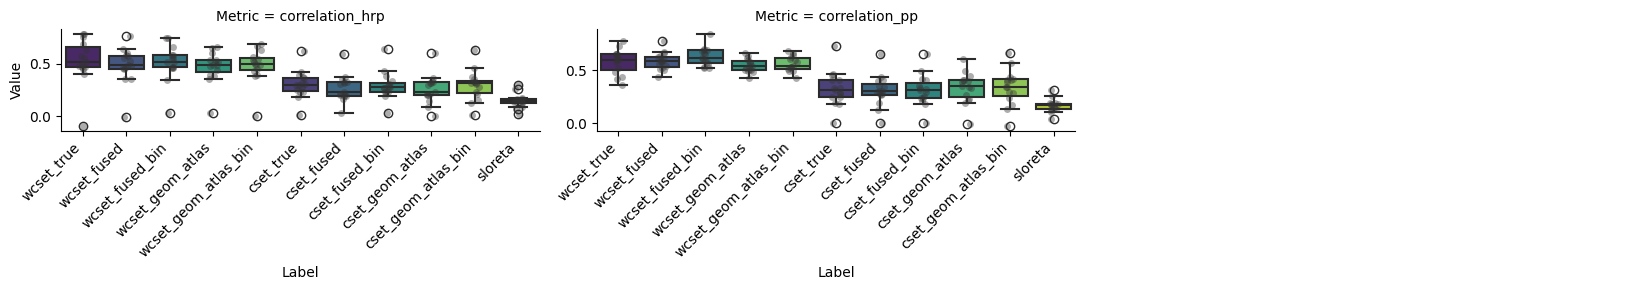

In [8]:
connectome_order = ["true", "fused", "fused_bin", "geom_atlas", "geom_atlas_bin"]
label_order = [f"wcset_{c}" for c in connectome_order] + [f"cset_{c}" for c in connectome_order] + ["sloreta"]

fig = metrics.plot(metrics=["correlation_hrp", "correlation_pp"], kind="box", aspect=1.8, order=label_order)
for ax in fig.axes:
    ax.tick_params(axis="x", rotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment("right")
fig.tight_layout()

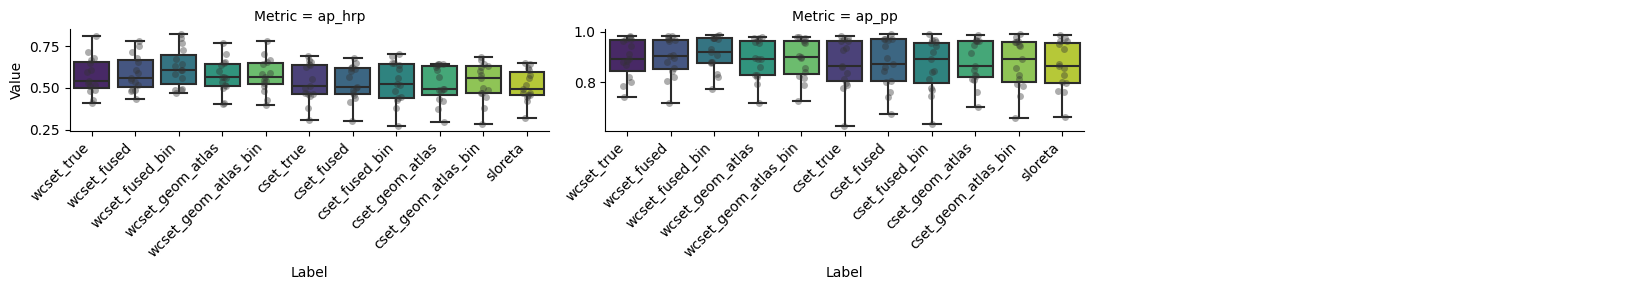

In [9]:
fig = metrics.plot(metrics=["ap_hrp", "ap_pp"], kind="box", aspect=1.8, order=label_order)
for ax in fig.axes:
    ax.tick_params(axis="x", rotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment("right")
fig.tight_layout()

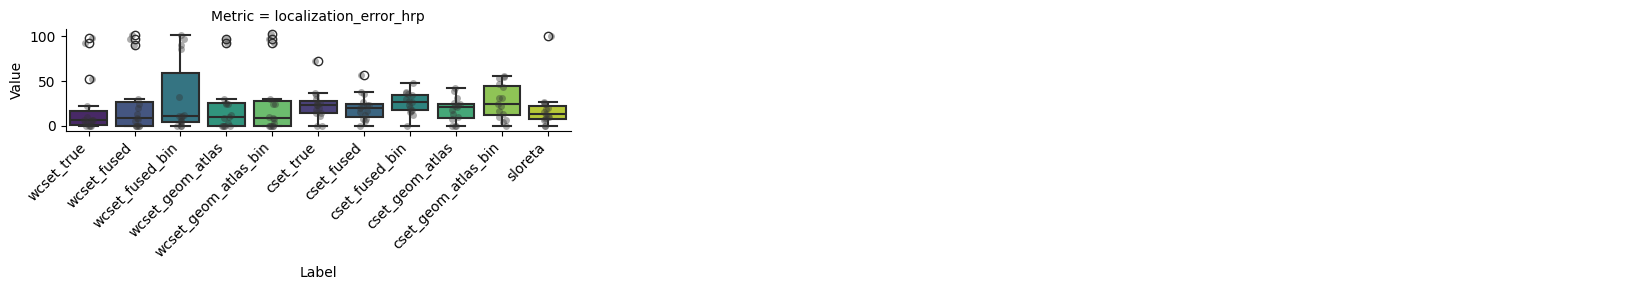

In [10]:
fig = metrics.plot(metrics=["localization_error_hrp"], kind="box", aspect=1.8, order=label_order)
for ax in fig.axes:
    ax.tick_params(axis="x", rotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment("right")
fig.tight_layout()

In [11]:
pd.set_option("display.width", 120)
df = metrics.get_filtered_df()
summary_table = df.groupby(["Metric", "Label"])["Value"].agg(["median", "mean", "std", "count"]).round(3)
for metric in ["correlation_hrp", "correlation_pp", "localization_error_hrp", "ap_hrp", "ap_pp"]:
    print(f"--- {metric} ---")
    print(summary_table.loc[metric].sort_values("median", ascending=False))
    print()

--- correlation_hrp ---
                      median   mean    std  count
Label                                            
wcset_fused_bin        0.516  0.513  0.171     15
wcset_true             0.512  0.529  0.214     15
wcset_geom_atlas_bin   0.494  0.485  0.162     15
wcset_geom_atlas       0.488  0.472  0.151     15
wcset_fused            0.486  0.485  0.174     15
cset_geom_atlas_bin    0.319  0.294  0.145     15
cset_true              0.301  0.304  0.133     15
cset_fused_bin         0.279  0.293  0.130     15
cset_fused             0.233  0.268  0.127     15
cset_geom_atlas        0.227  0.257  0.139     15
sloreta                0.142  0.147  0.067     15

--- correlation_pp ---
                      median   mean    std  count
Label                                            
wcset_fused_bin        0.618  0.628  0.087     15
wcset_true             0.596  0.579  0.115     15
wcset_fused            0.582  0.584  0.084     15
wcset_geom_atlas       0.540  0.545  0.064     15
wc